# 📖📖 MACHINE LEARNING PROJECT OF TITANIC DATASET:📖📖
 
 The Titanic dataset contains information about passengers, including their age, gender, passenger class, ticket fare, and survival status.

It is commonly used in machine learning classification because the target variable, Survived, has two possible outcomes:

0 = Did not survive

1 = Survived

*Project objective*

To analyze passenger information and develop a machine learning model that predicts whether a passenger survived the Titanic disaster.

Import libarires

In [60]:
import numpy as np
import pandas as pd
import matplotlib as mpt
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Ignore warnings
warnings.filterwarnings('ignore')

# Set the warning filter to ignore FutureWarning
warnings.simplefilter(action="ignore", category=FutureWarning)

plt.rcParams["figure.figsize"] = [10, 5]




Observation:

All required libraries for data analysis, visualization, and preprocessing are imported successfully. Warnings are disabled to keep the output clean.

### 1. 📌 Problem Definition

**Description**

Problem Definition means clearly identifying what we want to solve.

In this project, we want to predict whether a Titanic passenger survived or did not survive based on passenger information such as age, gender, passenger class, and fare.

**Problem statement**

Develop a machine learning classification model that predicts the survival status of Titanic passengers using historical passenger data.

**Target variable**

---Survived = 1

Passenger survived

----Survived = 0

Passenger did not survive

**Type of machine learning**

Supervised Learning → Binary Classification

In [61]:
# Define the project objective

problem_type = "Binary Classification"
target_column = "Survived"

print("Project: Titanic Survival Prediction")
print("Problem Type:", problem_type)
print("Target Column:", target_column)
print("Goal: Predict whether a passenger survived or not.")

Project: Titanic Survival Prediction
Problem Type: Binary Classification
Target Column: Survived
Goal: Predict whether a passenger survived or not.


Observation

The project is a binary classification problem because the target variable has two possible outcomes: survived or did not survive.

### 2. 📌 Data Collection
**Description**

Data Collection means obtaining the dataset that will be used for analysis and model training.

We will load the Titanic CSV file using Pandas.

 🔃 Load datasets📌

In [62]:
df = pd.read_csv("Titanic-Dataset.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Observation: 

The Titanic CSV file is loaded into the DataFrame df. The dataset is now ready for analysis.

📌 Basic Dataset Overview📌

In [63]:
#disply First 5 Rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [64]:
#disply last 5 rows
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [65]:
#Disply Random Sample
df.sample()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
345,346,1,2,"Brown, Miss. Amelia ""Mildred""",female,24.0,0,0,248733,13.0,F33,S


In [66]:
#dataset shape 
df.shape

(891, 12)

In [67]:
#Dataset column
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [68]:
#rows or column info
df.rmod

<bound method DataFrame.rmod of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                   

### 3. 📌 Data Understanding

**Description**

Data Understanding means studying the dataset to understand its structure, columns, data types, and values before cleaning.

In [69]:
#Data type
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [70]:
#dataset info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [71]:
# describe
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [72]:
#Statistical summary including categorical columns
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [73]:
df.describe(include="all")

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


Observation:

1- df.head()

Observation: Displays the first 5 rows of the Titanic dataset. It gives an initial view of the data and column values.

2- df.tail()

Observation: Displays the last 5 rows of the dataset. It helps verify the ending records.

3- df.sample()

Observation: Displays a random row from the dataset. It provides a quick random view of the data.

4- df.shape

Observation: Shows the total number of rows and columns in the dataset. It helps understand the dataset size.
5- df.columns

Observation: Displays all column names in the Titanic dataset. It helps identify available features.

6- df.info()

Observation: Provides information about columns, data types, non-null values, and memory usage. It helps identify missing values and incorrect data types.

7- df.dtypes

Observation: Displays the data type of every column. Numerical and categorical columns can be identified.

8- df.info()

Observation: Shows the complete structure of the dataset. It is useful for checking data types and missing observations.

9- df.describe()

Observation: Provides statistical summaries such as mean, standard deviation, minimum, and maximum. It helps understand numerical feature distributions.

In [74]:
#check non missing values
df.notnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,True,True,True,True,True,True,True,True,True,True,False,True
1,True,True,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,False,True
3,True,True,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,True,True,True,True,True,True,True,True,True,True,False,True
887,True,True,True,True,True,True,True,True,True,True,True,True
888,True,True,True,True,True,False,True,True,True,True,False,True
889,True,True,True,True,True,True,True,True,True,True,True,True


In [75]:
#unique value
df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [76]:
#missing value 
df.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [77]:
#Check duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [78]:
#unique values
for column in df.columns:
    print(f"\nColumn: {column}")
    print(df[column].unique()[:20])


Column: PassengerId
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]

Column: Survived
[0 1]

Column: Pclass
[3 1 2]

Column: Name
<StringArray>
[                                'Braund, Mr. Owen Harris',
     'Cumings, Mrs. John Bradley (Florence Briggs Thayer)',
                                  'Heikkinen, Miss. Laina',
            'Futrelle, Mrs. Jacques Heath (Lily May Peel)',
                                'Allen, Mr. William Henry',
                                        'Moran, Mr. James',
                                 'McCarthy, Mr. Timothy J',
                          'Palsson, Master. Gosta Leonard',
       'Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)',
                     'Nasser, Mrs. Nicholas (Adele Achem)',
                         'Sandstrom, Miss. Marguerite Rut',
                                'Bonnell, Miss. Elizabeth',
                          'Saundercock, Mr. William Henry',
                             'Andersson, Mr. Anders Johan',
 

In [79]:
df.sample()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
64,65,0,1,"Stewart, Mr. Albert A",male,NaN,0,0,PC 17605,27.7208,NaN,C


In [80]:
# Count missing values in every column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [81]:
# Calculate missing value percentage
missing_count = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percentage
})

missing_table = missing_table[
    missing_table['Missing Values'] > 0
]

print(missing_table)

          Missing Values  Percentage
Age                  177   19.865320
Cabin                687   77.104377
Embarked               2    0.224467


In [82]:
#duplicate values
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool

In [83]:
#Check target distribution
print(df["Survived"].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [84]:
#Target Percentage
print(df["Survived"].value_counts(normalize=True) * 100)

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


Observation:

The dataset contains passenger information and a survival target. info() shows data types and missing values, while describe() provides statistical information. The target distribution helps us understand how many passengers survived and did not survive.

### 4. 📌 Data Cleaning

**Description**

Data Cleaning means removing or correcting problems in the dataset, such as duplicate records, unnecessary columns, and missing values.

**For Titanic, we will:**

1- Remove the unnecessary PassengerId column.

2- Remove Name, Ticket, and Cabin from the initial modeling dataset.

3- Fill missing numerical values with the median.

4- Fill missing categorical values with the most frequent value.

5- Check for duplicates.

**Important note**

We will not modify the original dataset. We will create a separate copy for cleaning.

In [85]:
#Create a copy
df_clean = df.copy()

In [86]:
#Check Missing Vlaues
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [87]:
#Remove unnecessary columns
columns_to_drop = ["PassengerId", "Name", "Ticket", "Cabin"]

df_clean = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Remaining columns:")
print(df_clean.columns.tolist())

Remaining columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


In [88]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (891, 12)


In [89]:
# Memory usage of each column
df.memory_usage()

Index           132
PassengerId    7128
Survived       7128
Pclass         7128
Name           7128
Sex            7128
Age            7128
SibSp          7128
Parch          7128
Ticket         7128
Fare           7128
Cabin          7128
Embarked       7128
dtype: int64

In [90]:
# Total memory usage
df.memory_usage().sum()

np.int64(85668)

In [91]:
#Check Duplicate
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 111


In [92]:
#Remove Duplicate
df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows after cleaning: 0


In [93]:
#Fill missing Numerical Values
numeric_columns = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [94]:
#Fill  missing categorical values
categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

In [95]:
#check missing values after cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [96]:
#Display clean data
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


Observation:

Unnecessary columns are removed, duplicate records are handled, and missing values are filled. The cleaned dataset is now ready for preprocessing.

1- df.notnull()

Observation: Returns True for values that are not missing and False for missing values. It helps locate available data.

2-  df.nunique()

Observation: Shows the number of unique values in each column. It helps identify categorical and numerical features.

3-  df.isnull()

Observation: Returns True where values are missing. It helps locate missing data in the dataset.

4- df.sample()

Observation: Displays a random sample of Titanic passengers. It provides another quick look at individual records.

5- df.isnull().sum()

Observation: Counts missing values in every column. This identifies which columns require missing-value treatment.

6- Missing Percentage

Observation: Calculates both the number and percentage of missing values in each column. This helps decide whether to fill or remove a column.

7- df.duplicated()

Observation: Identifies duplicate rows in the dataset. True indicates that a row is duplicated.

8- df.drop_duplicates()

Observation: Removes duplicate rows from the dataset. The new shape shows the dataset size after removing duplicates.

9- df.memory_usage()

Observation: Shows the memory used by each DataFrame column. It helps understand memory consumption.

10- df.memory_usage().sum()

Observation: Calculates the total memory used by the DataFrame. It gives the overall memory requirement.

### 5. 📌 Data Preprocessing

**Description**

Data Preprocessing means converting the cleaned data into a format suitable for machine learning.

**In this step, we will:**

1- Separate features and target.

2- Split the dataset into training and testing sets.

3- Encode categorical variables.

4- Scale numerical variables.

5- Handle missing values using a pipeline.

**Why preprocessing is needed**

Machine learning models work with numerical data. For example:

Sex = male/female → numerical encoding

Embarked = S/C/Q → one-hot encoding

Age and Fare → numerical scaling

In [97]:
#Separate Feature And Target Column
target_column = "Survived"

X = df_clean.drop(columns=[target_column])
y = df_clean[target_column]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (780, 7)
Target shape: (780,)


In [98]:
#Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (624, 7)
Testing features: (156, 7)
Training target: (624,)
Testing target: (156,)


In [99]:
#Identify Numerical And Categorical Column

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Sex', 'Embarked']


In [100]:
#Create Preprocessing Pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [101]:
#Transform Traning and Testing Data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (624, 10)
Processed testing shape: (156, 10)


Observation:

The dataset is divided into training and testing sets. Numerical features are scaled, categorical features are encoded, and the preprocessing pipeline ensures that the same transformations are applied consistently.

### 6- 📌Exploratory Data Analysis (EDA)

Descrition:

Exploratory Data Analysis (EDA) is the process of exploring and understanding a dataset before applying machine learning algorithms. In the Titanic dataset, EDA is used to understand passenger information, survival patterns, missing values, distributions, relationships, and important features that may affect survival.

The Titanic dataset contains information about passengers who traveled on the Titanic. The main objective is to analyze the factors that influenced whether a passenger survived (1) or did not survive (0).

**1- Survival Analysis**

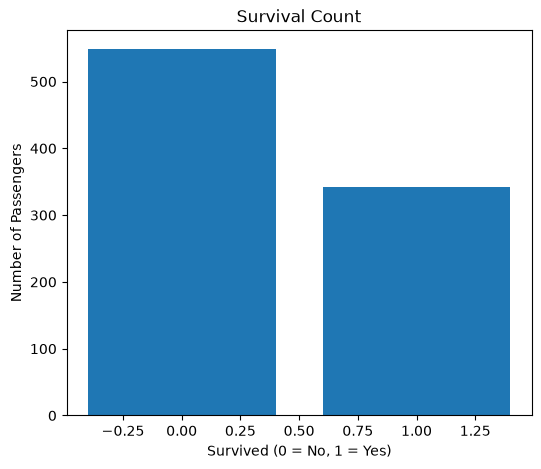

In [102]:
#survival Count Bar Chart
survival = df["Survived"].value_counts()

plt.figure(figsize=(6,5))
plt.bar(survival.index, survival.values)

plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

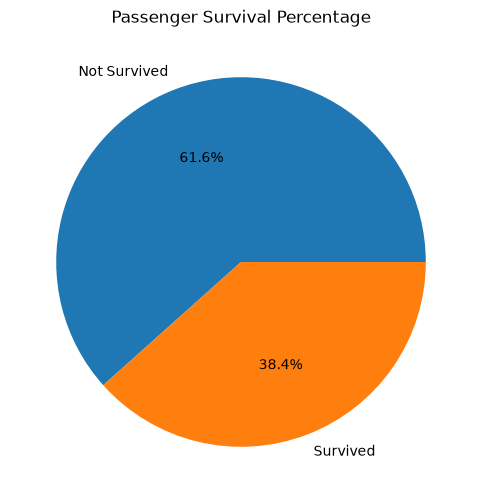

In [103]:
# Survival pie Chart
survival = df["Survived"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    survival.values,
    labels=["Not Survived","Survived"],
    autopct="%1.1f%%"
)

plt.title("Passenger Survival Percentage")
plt.show()

Observation: Counts passengers according to their survival status. It shows how many passengers survived and did not survive.

1- Survival Bar Chart

Observation: The bar chart visually compares survivors and non-survivors. Non-survivors are more numerous.

2- Survival Pie Chart

Observation: The pie chart displays the percentage of passengers who survived and did not survive. It provides a visual proportion of survival.

**2- Passenger Age Analysis**

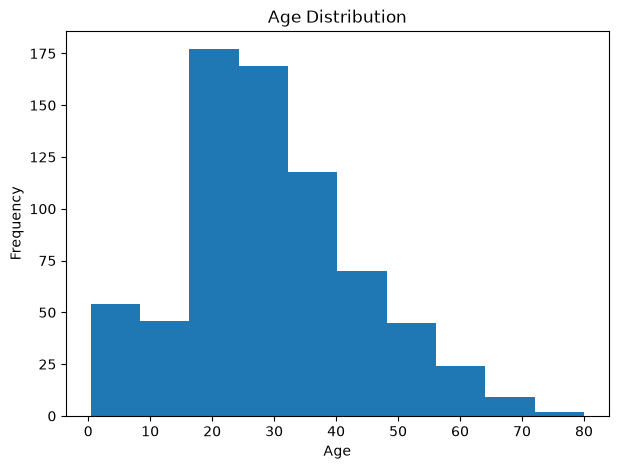

In [104]:
#Age Histogram Chart
plt.figure(figsize=(7,5))

plt.hist(df["Age"].dropna(), bins=10)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

Observation:

The histogram shows the distribution of passenger ages. Most passengers are concentrated within the younger and middle-age ranges.

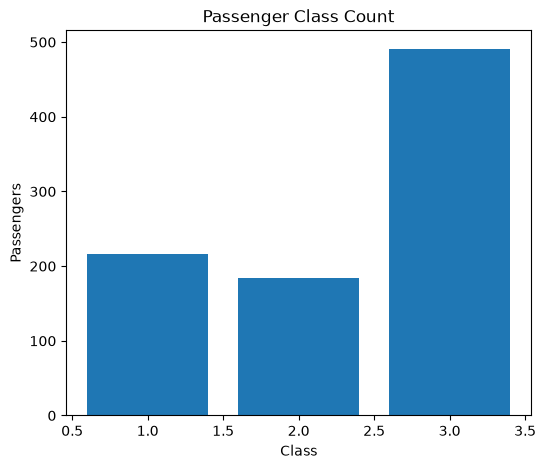

In [105]:
#Passenger Analysis
pclass = df["Pclass"].value_counts()

plt.figure(figsize=(6,5))

plt.bar(pclass.index, pclass.values)

plt.title("Passenger Class Count")
plt.xlabel("Class")
plt.ylabel("Passengers")

plt.show()

Observation: 

Counts passengers in each class. Class 3 contains the largest number of passengers.

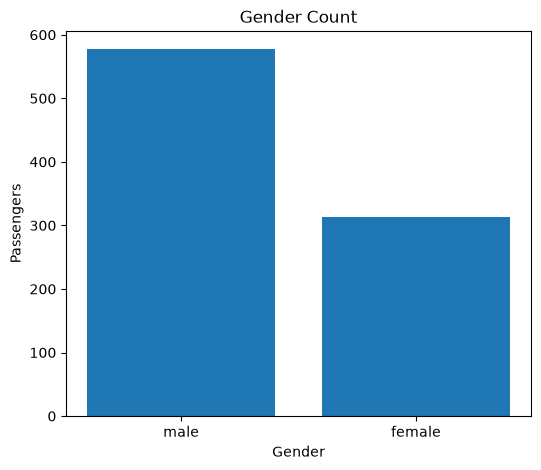

In [106]:
#Gender Analysis
gender = df["Sex"].value_counts()

plt.figure(figsize=(6,5))

plt.bar(gender.index, gender.values)

plt.title("Gender Count")
plt.xlabel("Gender")
plt.ylabel("Passengers")

plt.show()

Observation: 

Shows the number of male and female passengers. Male passengers are more numerous in the dataset.

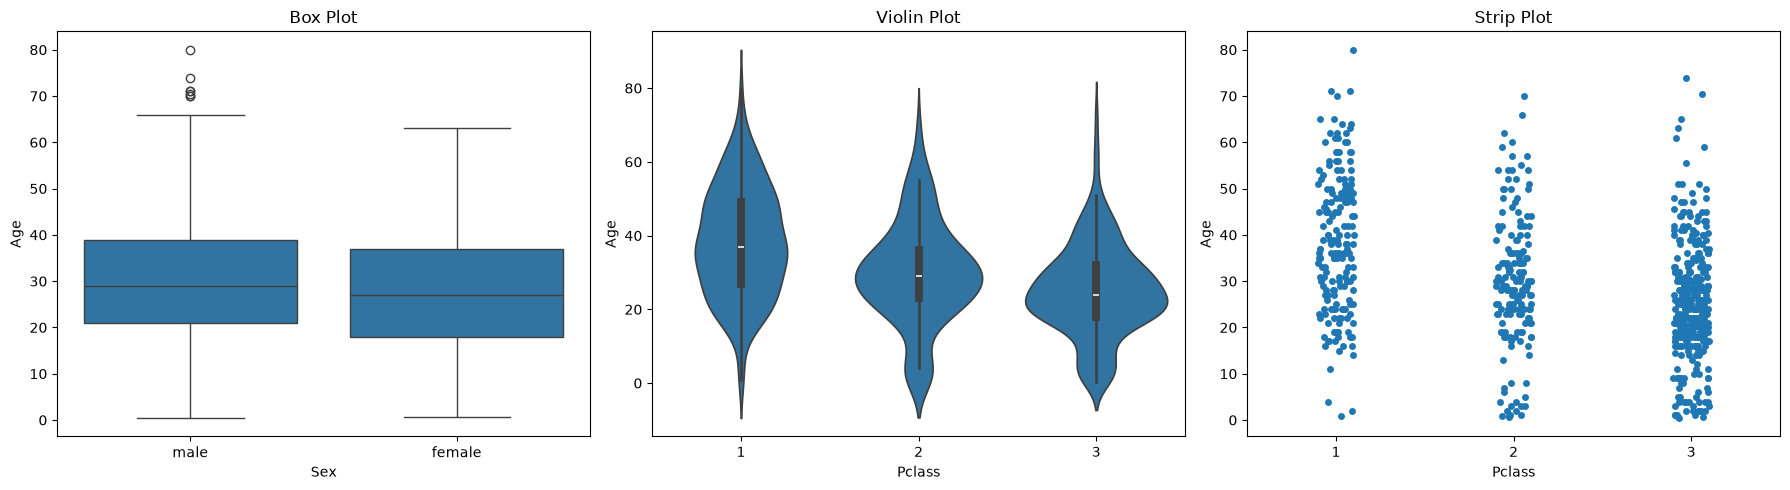

In [107]:
#3 graph
plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
sns.boxplot(x="Sex", y="Age", data=df)
plt.title("Box Plot")

plt.subplot(1,3,2)
sns.violinplot(x="Pclass", y="Age", data=df)
plt.title("Violin Plot")

plt.subplot(1,3,3)
sns.stripplot(x="Pclass", y="Age", data=df)
plt.title("Strip Plot")

plt.tight_layout()
plt.show()

Observation:

1- Box Plot

Observation: The box plot shows the age distribution by gender. It also helps identify possible age outliers.

2- Violin Plot

Observation: The violin plot shows the distribution of passenger ages across different classes. It provides information about density and spread.

3- Strip Plot

Observation: The strip plot displays individual passenger ages for each class. It helps visualize the spread and concentration of observations.

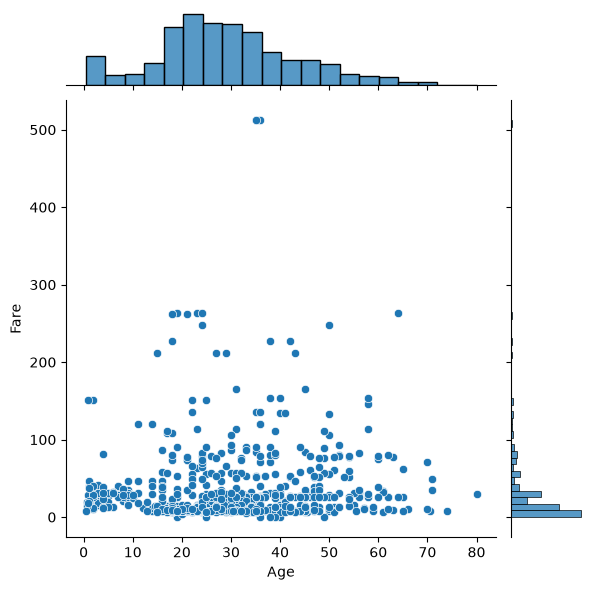

In [108]:
#join plot
sns.jointplot(data=df, x="Age", y="Fare", kind="scatter")
plt.show()

Observation:

The joint plot shows the relationship between Age and Fare. It also displays the individual distributions of both variables.

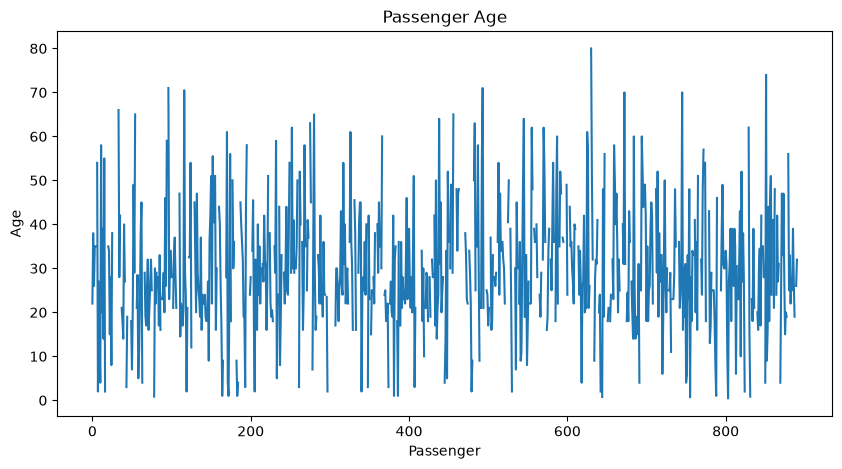

In [ ]:
#line chart
plt.figure(figsize=(10,5))

plt.plot(df["Age"])

plt.title("Passenger Age")
plt.xlabel("Passenger")
plt.ylabel("Age")

plt.show()

Observation: 

The line chart displays passenger ages according to their row order. It shows how age values vary across records.

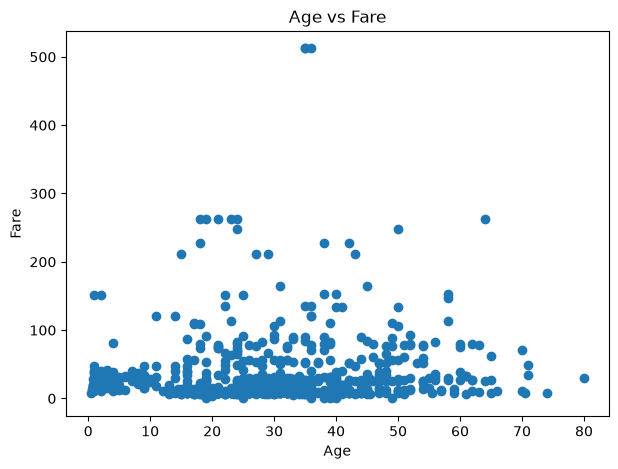

In [ ]:
#Scatter graph
plt.figure(figsize=(7,5))

plt.scatter(df["Age"], df["Fare"])

plt.title("Age vs Fare")

plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

Observation:

The scatter plot shows the relationship between age and fare. High fares occur across different age groups.

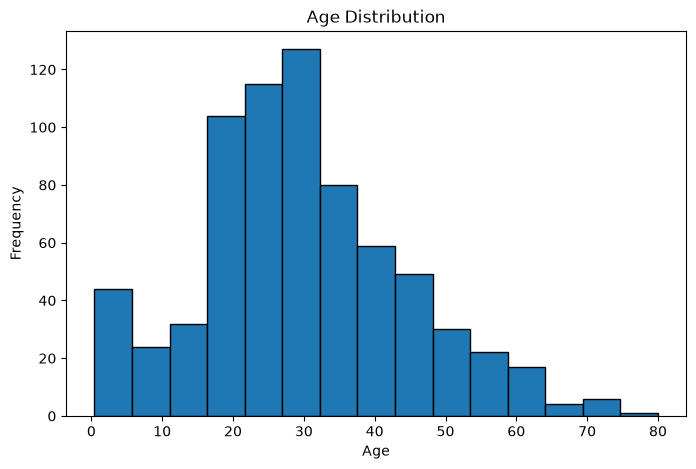

In [ ]:
#histogram chart
plt.figure(figsize=(8,5))

plt.hist(df["Age"].dropna(), bins=15, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

Observation:
 
The histogram displays the frequency of passengers across age groups. It helps understand the overall age distribution.

**3- Fare Analysis**

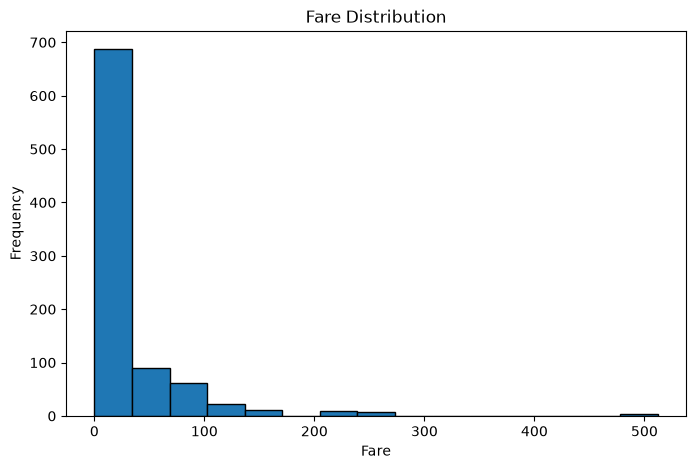

In [ ]:
#fare histogram
plt.figure(figsize=(8,5))

plt.hist(df["Fare"], bins=15, edgecolor="black")

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

Observation: 

The fare distribution is strongly right-skewed. Most passengers paid lower fares, while a few paid very high fares.

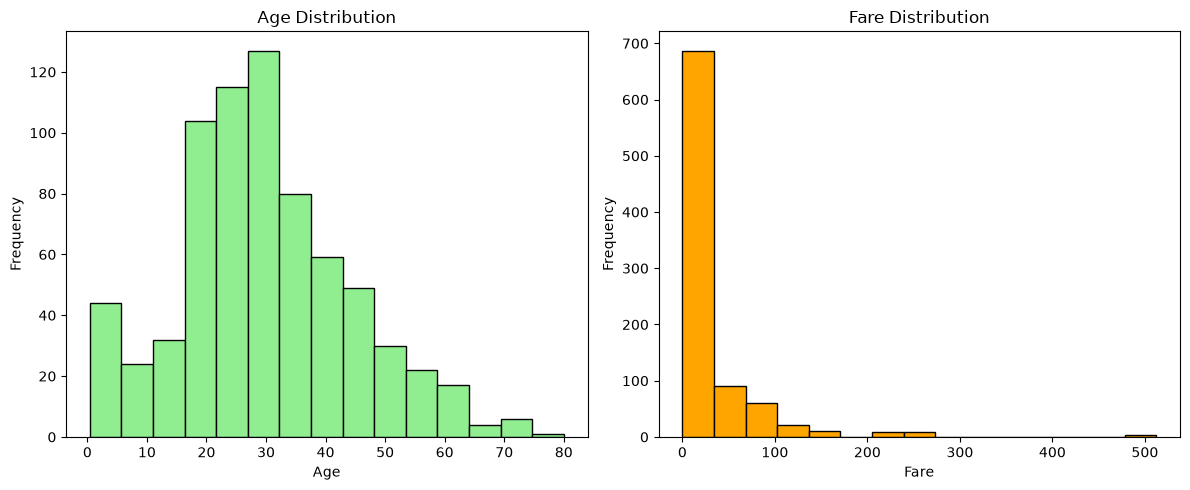

In [ ]:
plt.figure(figsize=(12,5))

# Age Histogram
plt.subplot(1,2,1)
plt.hist(df["Age"].dropna(), bins=15, color="lightgreen", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

# Fare Histogram
plt.subplot(1,2,2)
plt.hist(df["Fare"], bins=15, color="orange", edgecolor="black")
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Observation:

 The two histograms compare age and fare distributions. Fare contains more extreme values than age.

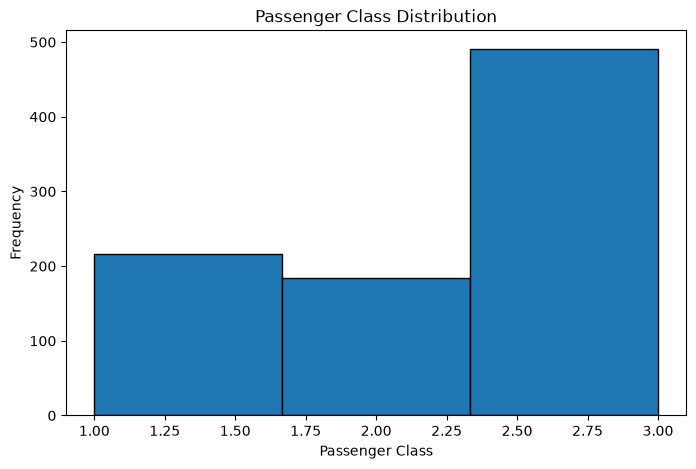

In [ ]:
#Passenger Analysis
plt.figure(figsize=(8,5))

plt.hist(df["Pclass"], bins=3, edgecolor="black")

plt.title("Passenger Class Distribution")
plt.xlabel("Passenger Class")
plt.ylabel("Frequency")

plt.show()

Observation: 

The histogram shows the distribution of passenger classes. Class 3 has the highest number of passengers.

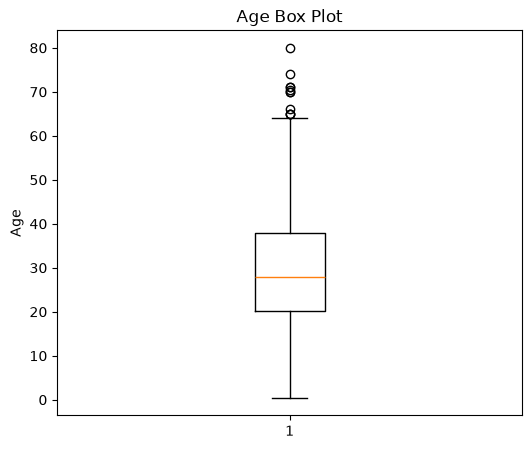

In [ ]:
#Box plot
plt.figure(figsize=(6,5))

plt.boxplot(df["Age"].dropna())

plt.title("Age Box Plot")

plt.ylabel("Age")

plt.show()

Observation:

The box plot summarizes the age distribution and identifies potential age outliers.

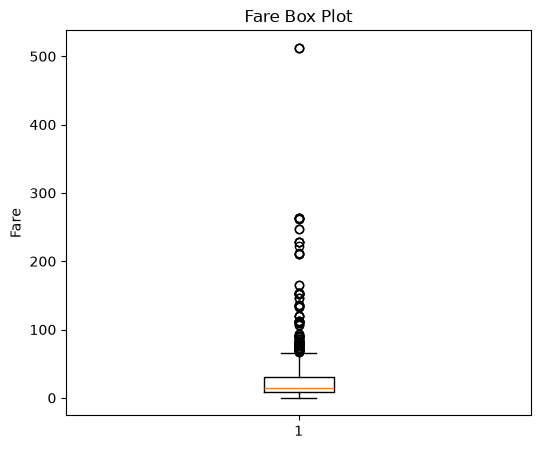

In [ ]:
#Fare Box plot
plt.figure(figsize=(6,5))

plt.boxplot(df["Fare"])

plt.title("Fare Box Plot")

plt.ylabel("Fare")

plt.show()

Observation: The fare box plot shows several high-value outliers. This confirms that fare data contains extreme values.

**4- Embarked Port Analysis**

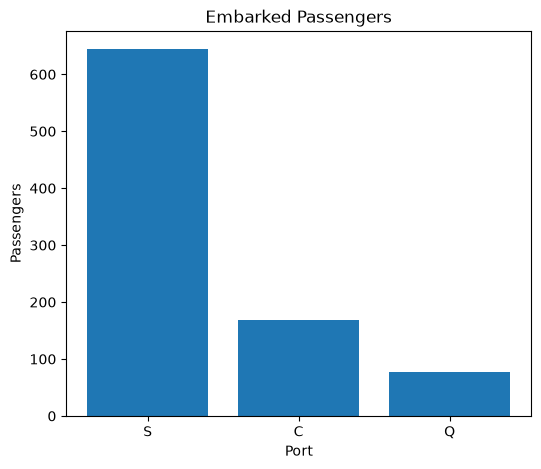

In [ ]:
#Embareked Passenger 
embarked = df["Embarked"].value_counts()

plt.figure(figsize=(6,5))

plt.bar(embarked.index, embarked.values)

plt.title("Embarked Passengers")

plt.xlabel("Port")

plt.ylabel("Passengers")

plt.show()

Observation:

 The bar chart shows the number of passengers from each embarkation port. One port has considerably more passengers than the others.

**5- Siblings and Spouses Analysis**

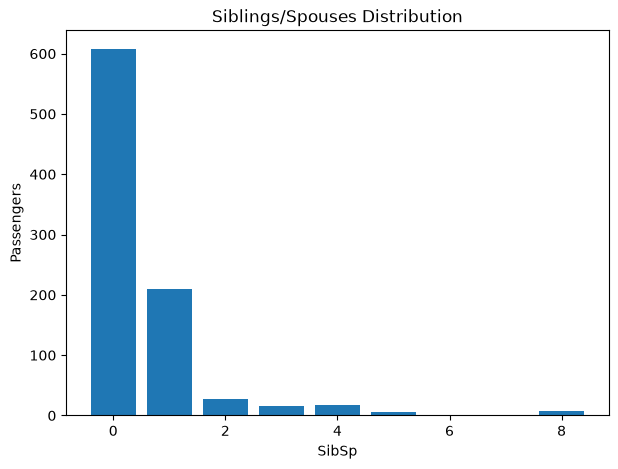

In [ ]:
sib = df["SibSp"].value_counts().sort_index()

plt.figure(figsize=(7,5))

plt.bar(sib.index, sib.values)

plt.title("Siblings/Spouses Distribution")

plt.xlabel("SibSp")

plt.ylabel("Passengers")

plt.show()

Observation: Most passengers have zero siblings or spouses aboard. Higher SibSp values occur less frequently.

**6- Multivariate Visualization**

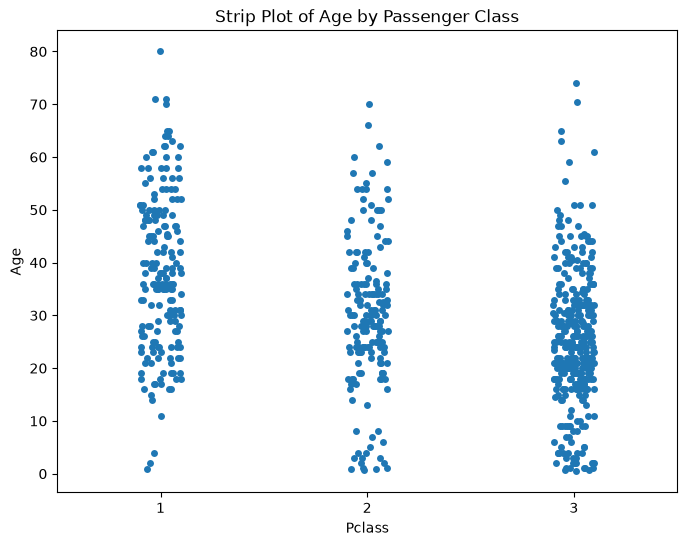

In [ ]:
#Strip Plot by Survival
plt.figure(figsize=(8,6))

sns.stripplot(x="Pclass", y="Age", data=df)

plt.title("Strip Plot of Age by Passenger Class")
plt.show()

Observation:

Passenger ages are compared across passenger classes. It shows how age values are distributed within each class.

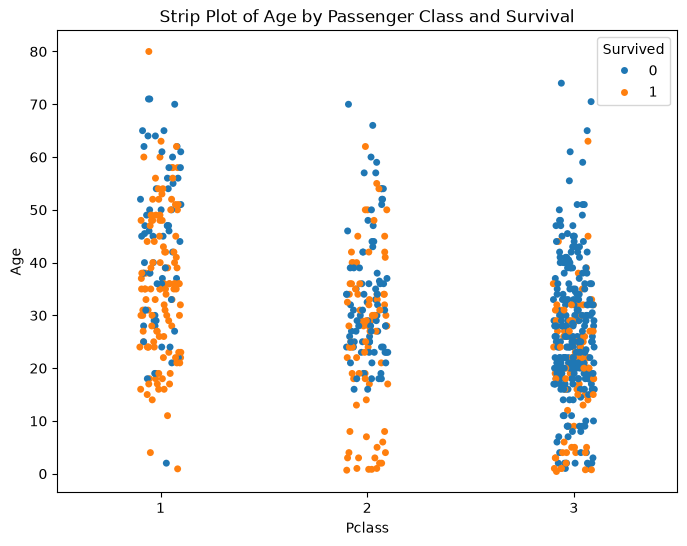

In [ ]:
#multivarient
plt.figure(figsize=(8,6))

sns.stripplot(
    x="Pclass",
    y="Age",
    hue="Survived",
    data=df,
    jitter=True
)

plt.title("Strip Plot of Age by Passenger Class and Survival")
plt.show()

Observation: 

Adding survival separates passengers according to survival status. This helps identify survival patterns across classes and ages.

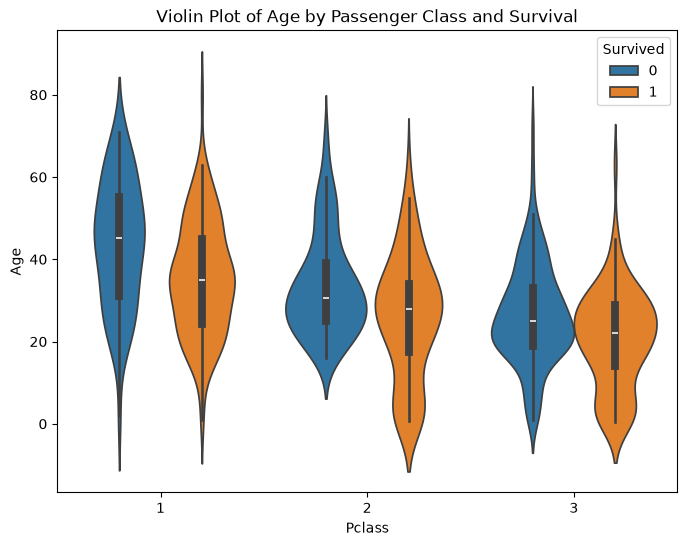

In [ ]:
#violin plot by Survied
plt.figure(figsize=(8,6))

sns.violinplot(
    x="Pclass",
    y="Age",
    hue="Survived",
    data=df
)

plt.title("Violin Plot of Age by Passenger Class and Survival")
plt.show()

Observation:

The violin plot compares age distributions of survivors and non-survivors across passenger classes. It shows differences in distribution and density.

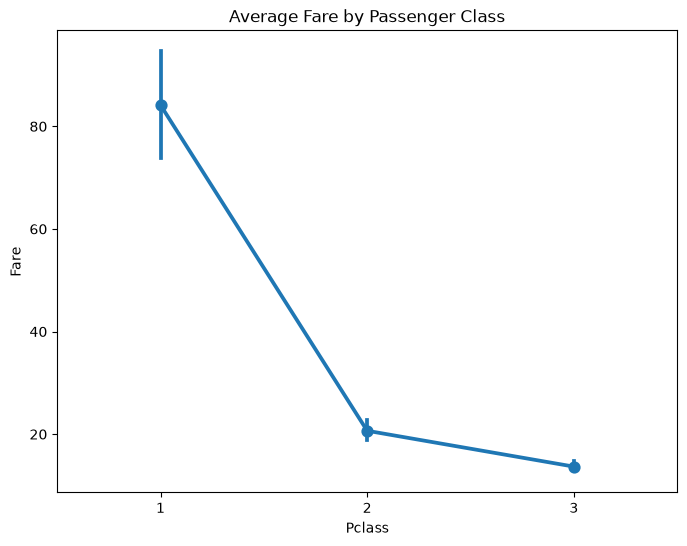

In [ ]:
#point plot
plt.figure(figsize=(8,6))

sns.pointplot(
    x="Pclass",
    y="Fare",
    data=df
)

plt.title("Average Fare by Passenger Class")
plt.show()

Observation: 

The point plot displays average fare for each passenger class. Higher passenger classes generally have higher average fares.

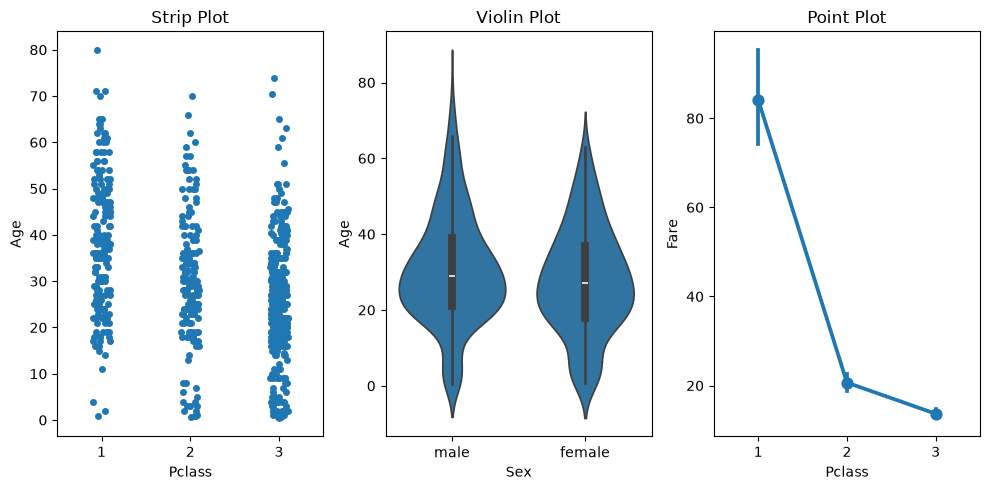

In [ ]:
#3 graph

# Strip Plot
plt.subplot(1,3,1)
sns.stripplot(x="Pclass", y="Age", data=df)
plt.title("Strip Plot")

# Violin Plot
plt.subplot(1,3,2)
sns.violinplot(x="Sex", y="Age", data=df)
plt.title("Violin Plot")

# Point Plot
plt.subplot(1,3,3)
sns.pointplot(x="Pclass", y="Fare", data=df)
plt.title("Point Plot")

plt.tight_layout()
plt.show()

Observation:

Strip, violin, and point plots provide different views of passenger age, gender, class, and fare. Together they help understand multivariate relationships.

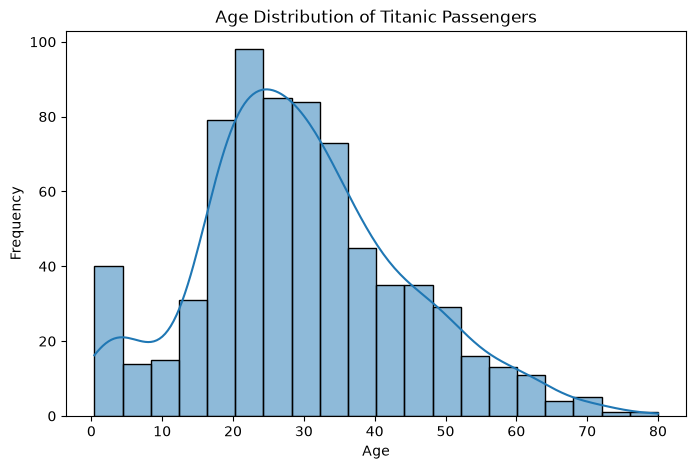

In [ ]:
#Distribution graph
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()


Observation:

The histogram and KDE curve show the shape of the passenger age distribution. Most passengers fall within the younger and middle-age ranges.

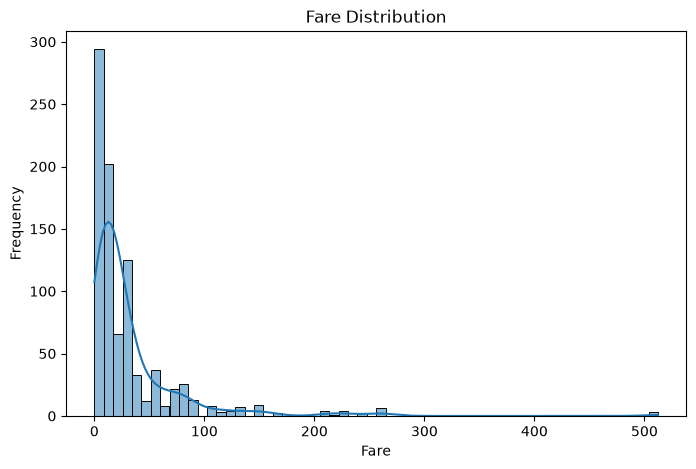

In [ ]:
#Distribution graph of fare
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Fare",
    kde=True
)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

Observation:
 
The KDE confirms that fare is positively skewed. A small number of very expensive fares create the long right tail.

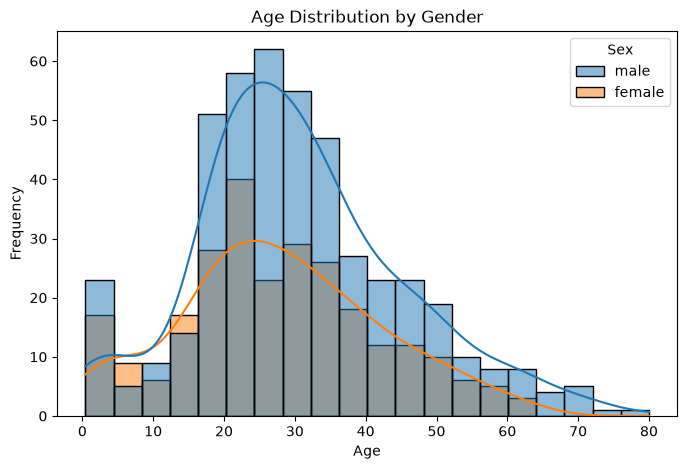

In [ ]:
#Distribution graph gender
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Sex",
    kde=True
)

plt.title("Age Distribution by Gender")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

Observation: 

Age distributions differ between male and female passengers. The KDE curves make these differences easier to compare.

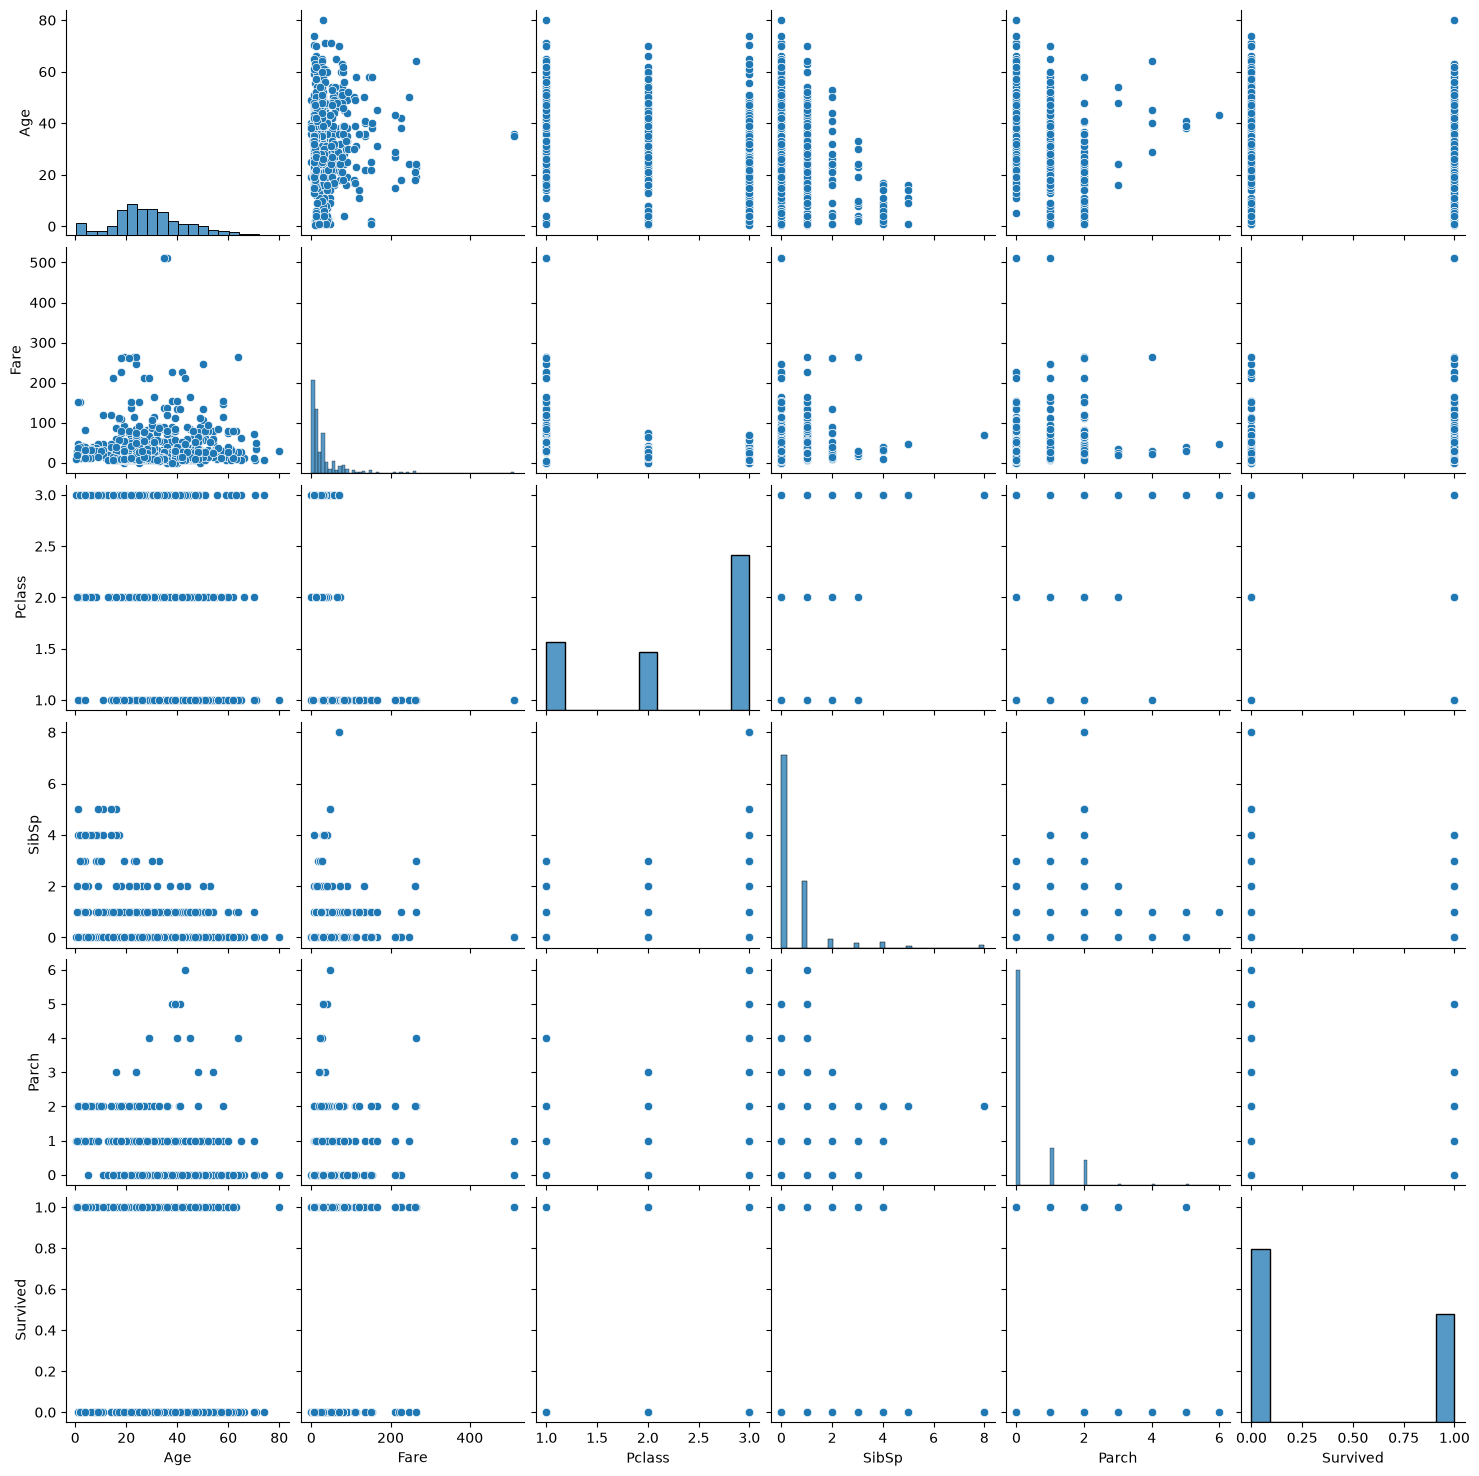

In [ ]:
#pair plot
sns.pairplot(
    df[["Age", "Fare", "Pclass", "SibSp", "Parch", "Survived"]]
)

plt.show()

Observation: 

The pair plot shows relationships between numerical features such as age, fare, class, and family-related variables. It helps identify patterns and correlations.

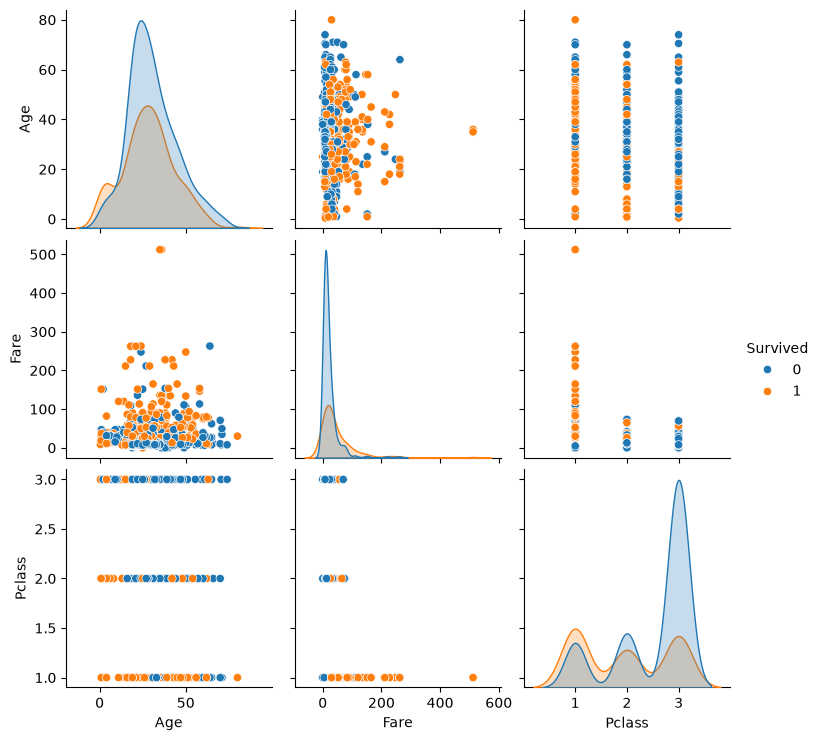

In [ ]:
#pair plot
sns.pairplot(
    df[["Age", "Fare", "Pclass", "Survived"]],
    hue="Survived"
)

plt.show()

Observation: 

Coloring observations by survival makes it easier to identify feature patterns associated with survival.

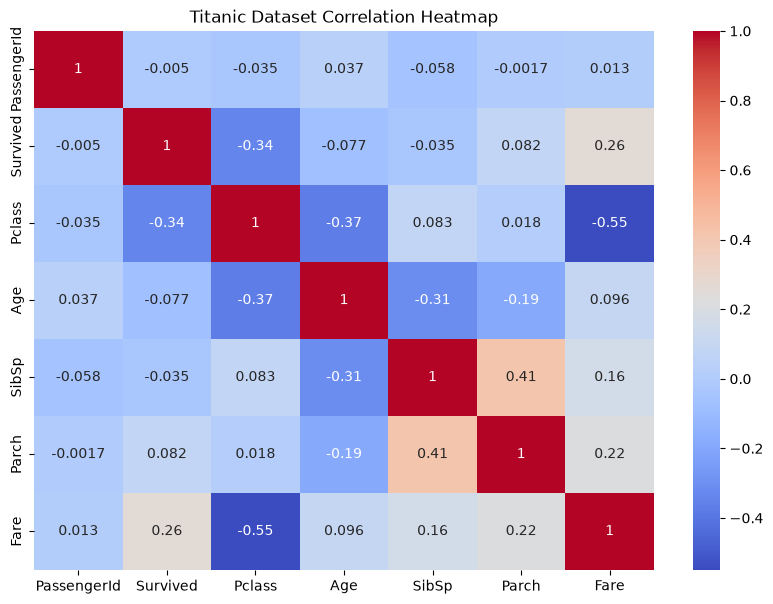

In [ ]:
#Heatmap  graph
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Titanic Dataset Correlation Heatmap")
plt.show()

Observation: 

The heatmap displays correlations between numerical variables. It helps identify positively and negatively related features.

### 7. 📌 Feature Engineering And Selection

**Description**

Feature Engineering means creating new useful features from existing data to improve model performance.

For Titanic, we can create:

1- FamilySize

2- IsAlone

3- Title

4- FarePerPerson

In [ ]:
#label encoding by sex
df ['Sex']

0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: str

Observation: Displays the Sex column to examine its categorical values before encoding.

In [ ]:
full_data = df.copy()

Observation: Creates a copy of the original dataset. This protects the original DataFrame from direct modifications.

In [ ]:
le = LabelEncoder()
full_data['Sex'] = le.fit_transform(full_data['Sex'])

Observation: Converts the categorical Sex values into numerical labels. This makes the feature suitable for machine-learning algorithms.

In [ ]:
full_data.sample()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
332,333,0,1,"Graham, Mr. George Edward",1,38.0,0,1,PC 17582,153.4625,C91,S


In [ ]:
full_data['Embarked']

0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: str

Observation: Displays the Embarked column and its categorical values before encoding.

In [ ]:
Embarked_dummies = pd.get_dummies(df['Embarked'],prefix ='Embarked')

Observation: Converts Embarked categories into separate binary columns. Each port gets its own encoded feature.

In [ ]:
full_data=pd.concat ([full_data, Embarked_dummies], axis=1)
full_data.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Embarked_C,Embarked_Q,Embarked_S
820,821,1,1,"Hays, Mrs. Charles Melville (Clara Jennings Gr...",0,52.0,1,1,12749,93.5000,B69,S,False,False,True
532,533,0,3,"Elias, Mr. Joseph Jr",1,17.0,1,1,2690,7.2292,NaN,C,True,False,False
591,592,1,1,"Stephenson, Mrs. Walter Bertram (Martha Eustis)",0,52.0,1,0,36947,78.2667,D20,C,True,False,False
593,594,0,3,"Bourke, Miss. Mary",0,NaN,0,2,364848,7.7500,NaN,Q,False,True,False
608,609,1,2,"Laroche, Mrs. Joseph (Juliette Marie Louise La...",0,22.0,1,2,SC/Paris 2123,41.5792,NaN,C,True,False,False


Observation: The one-hot encoded columns are added to the copied dataset. The dataset now contains both original and encoded information.

In [53]:
#Create FamilySize
df_fe["FamilySize"] = df_fe["SibSp"] + df_fe["Parch"] + 1

In [54]:
#Create IsAlone
df_fe["IsAlone"] = (df_fe["FamilySize"] == 1).astype(int)

In [55]:
#Create FarePerPerson
df_fe["FarePerPerson"] = df_fe["Fare"] / df_fe["FamilySize"]

In [57]:
#Create Title
df_fe["Title"] = df_fe["Name"].str.extract(
    r",\s*([^.]*)\."
)[0].str.strip()

Observation

New features such as FamilySize and IsAlone provide additional information about passenger relationships and may improve prediction performance.

In [ ]:
#train  test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Observation: The data is divided into training and testing sets. Stratification maintains a similar survival distribution in both sets.

In [ ]:
#check missing values
# Count missing values in every column
missing_values = df.isnull().sum()

print(missing_values)

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


Observation: Missing values are counted for every column. This identifies features that require preprocessing.

In [ ]:
#calculate missing values percentage
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percentage
})

missing_table = missing_table[
    missing_table['Missing Values'] > 0
]

print(missing_table)

             Missing Values  Percentage
age                     177   19.865320
embarked                  2    0.224467
deck                    688   77.216611
embark_town               2    0.224467


Observation: The percentage of missing values is calculated for each column. This helps determine the appropriate missing-value strategy.

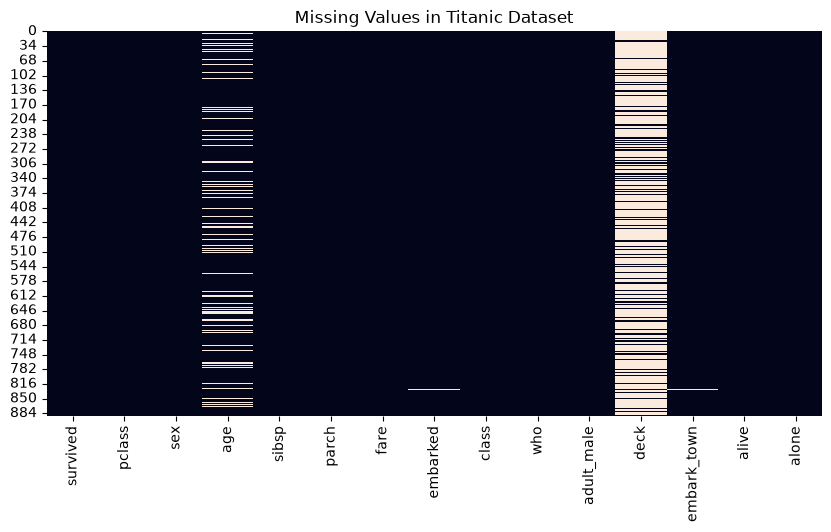

In [ ]:
#Visualize Missing Values
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.title("Missing Values in Titanic Dataset")
plt.show()

Observation: The heatmap visually displays missing values. Columns with many missing observations are easy to identify.

In [ ]:
#handle deck
# Check deck missing values
print("Missing deck values:",
      df['deck'].isnull().sum())

# Drop deck
df.drop(
    columns=['deck'],
    inplace=True
)

print("deck column removed.")

Missing deck values: 688
deck column removed.


Observation: The deck column contains a large number of missing values. This makes it difficult to reliably impute.

In [ ]:
#handle missing age
#median
age_median = df['age'].median()

print("Median Age:", age_median)
#fill
df['age'] = df['age'].fillna(age_median)

Median Age: 28.0


Observation: The deck column is removed because of its high amount of missing data. This simplifies the dataset.

In [ ]:
#check
print(
    "Missing age values:",
    df['age'].isnull().sum()
)

Missing age values: 0


Observation: The median age is calculated to use as a replacement for missing age values.

In [ ]:
#handle missing embarked
#mode
print("Embarked mode:")
print(df['embarked'].mode())
embarked_mode = df['embarked'].mode()[0]

print("Mode:", embarked_mode)
#fill the missing values
df['embarked'] = df['embarked'].fillna(
    embarked_mode
)

Embarked mode:
0    S
Name: embarked, dtype: str
Mode: S


Observation: Missing age values are replaced with the median age. This preserves all passenger records.

In [ ]:
#check
print(
    "Missing embarked values:",
    df['embarked'].isnull().sum()
)

Missing embarked values: 0


Observation: The check confirms whether missing values remain in the age column after imputation.

In [ ]:
#Handle Missing embark_town
#mode
print(df['embark_town'].mode())
#fill the missing values
df['embark_town'] = df['embark_town'].fillna(
    df['embark_town'].mode()[0]
)

0    Southampton
Name: embark_town, dtype: str


Observation: The most frequent Embarked value is calculated. The mode is used because this is a categorical feature.

In [ ]:
#check
print(
    "Missing embark_town values:",
    df['embark_town'].isnull().sum()
)

Missing embark_town values: 0


Observation: Missing Embarked values are replaced with the most frequent category.

In [ ]:
#check all missing values
print("Missing values after handling:\n")

print(df.isnull().sum())

Missing values after handling:

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


Observation: The result confirms whether missing Embarked values have been successfully handled.

In [ ]:
#check target values
df = sns.load_dataset("titanic")

print(df.columns.tolist())
print(df["survived"])



['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64


Observation: The survived column contains the target values. 0 represents non-survival and 1 represents survival.

In [ ]:
#Target values
print("Survival Distribution:")
print(df['survived'].value_counts())

print("\nSurvival Percentage:")
print(df['survived'].value_counts(normalize=True) * 100)



Survival Distribution:
survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


Observation: The value counts show the number of survivors and non-survivors. Non-survivors are more common.
Observation: The normalized counts show the percentage of passengers in each survival category.

In [ ]:
#Separate target and feature
# Target variable
y = df['survived']

# Features
X = df.drop('survived', axis=1)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 14)
Target Shape: (891,)


Observation: y contains the target variable survived, while X contains all input features.

In [ ]:
#Numeric Scaling — StandardScale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

Observation: Numerical missing values are replaced using the median and then standardized using StandardScaler.

In [ ]:
#Removed Deck
print("Missing values in deck:", df['deck'].isnull().sum())

X_clean = X.drop(columns=['deck'])

print("Old Shape:", X.shape)
print("New Shape:", X_clean.shape)

Missing values in deck: 688
Old Shape: (891, 14)
New Shape: (891, 13)


Observation: The deck column contains many missing values, making it less reliable for analysis. Removing deck decreases the number of features while eliminating a column with substantial missing data.

1- Split Traning and Testing data

In [ ]:
#split Traning and Testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 13)
Testing Data: (179, 13)


Observation: The data is split into 80% training and 20% testing data. Stratification preserves the survival distribution.

In [ ]:
#check column
print("Columns:")
print(X_train.columns.tolist())

Columns:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


Observation: The training columns are displayed to verify which features will be used during preprocessing.

In [ ]:
#numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

Observation: Numerical features are imputed using the median and standardized using StandardScaler.

In [ ]:
#categorical_transformer
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

Observation: Missing categorical values are filled with the most frequent category and then converted using one-hot encoding.

In [ ]:
# Numerical columns
numeric_features = ['age', 'fare', 'sibsp', 'parch']

# Categorical columns
categorical_features = ['sex', 'embarked', 'class', 'who', 'adult_male', 'alone']

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

Observation: age, fare, sibsp, and parch are selected as numerical features.sex, embarked, class, who, adult_male, and alone are selected as categorical features.

2-  Create Column Transfer

In [ ]:
# CREATE PREPROCESSOR

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

Observation: ColumnTransformer combines numerical and categorical preprocessing into one preprocessing pipeline.

3-  Apply preprocessing

In [ ]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

Observation: The preprocessor learns transformation parameters only from the training data. This prevents information leakage from the test set. The same preprocessing learned from training data is applied to the test data.

In [ ]:
#Get feature name
feature_names = preprocessor.get_feature_names_out()

print("Number of Features:", len(feature_names))
print(feature_names)

Number of Features: 20
['num__age' 'num__fare' 'num__sibsp' 'num__parch' 'cat__sex_female'
 'cat__sex_male' 'cat__embarked_C' 'cat__embarked_Q' 'cat__embarked_S'
 'cat__embarked_nan' 'cat__class_First' 'cat__class_Second'
 'cat__class_Third' 'cat__who_child' 'cat__who_man' 'cat__who_woman'
 'cat__adult_male_False' 'cat__adult_male_True' 'cat__alone_False'
 'cat__alone_True']


Observation: The final names of numerical and one-hot encoded features are extracted after preprocessing.

4-  Convert Processed Data Back to DataFrame

In [ ]:
#convert back to dataframe
X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed Training Data:")
X_train_df.head()

Processed Training Data:


,num__age,num__fare,num__sibsp,num__parch,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S,cat__embarked_nan,cat__class_First,cat__class_Second,cat__class_Third,cat__who_child,cat__who_man,cat__who_woman,cat__adult_male_False,cat__adult_male_True,cat__alone_False,cat__alone_True
692,NaN,0.513812,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
481,NaN,-0.662563,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
527,NaN,3.955399,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
855,-0.815864,-0.467874,-0.465084,0.727782,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
801,0.082384,-0.115977,0.478335,0.727782,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


Observation: The processed training array is converted into a DataFrame with meaningful feature names.

In [ ]:
#check missing values after preprocessing
print(
    "Missing values in training data:",
    X_train_df.isnull().sum().sum()
)

print(
    "Missing values in testing data:",
    X_test_df.isnull().sum().sum()
)

Missing values in training data: 137
Missing values in testing data: 40


Observation: The processed training and testing datasets are checked to ensure that preprocessing has removed missing values.

In [ ]:
#Binary Encoding
binary_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

Observation: A preprocessing pipeline is created to handle missing categorical values before binary encoding.

In [ ]:
#One hot encoding
#embarked
print("Unique Embarked values:")
print(titanic['Embarked'].unique())

embarked_dummies = pd.get_dummies(
    titanic['Embarked'],
    prefix='Embarked'
)

print("\nAfter One-Hot Encoding:")
print(embarked_dummies.head())

Unique Embarked values:
<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

After One-Hot Encoding:
   Embarked_C  Embarked_Q  Embarked_S
0       False       False        True
1        True       False       False
2       False       False        True
3       False       False        True
4       False       False        True


Observation: The unique embarkation categories are displayed before one-hot encoding.

5- Encoding Visualization Comparison

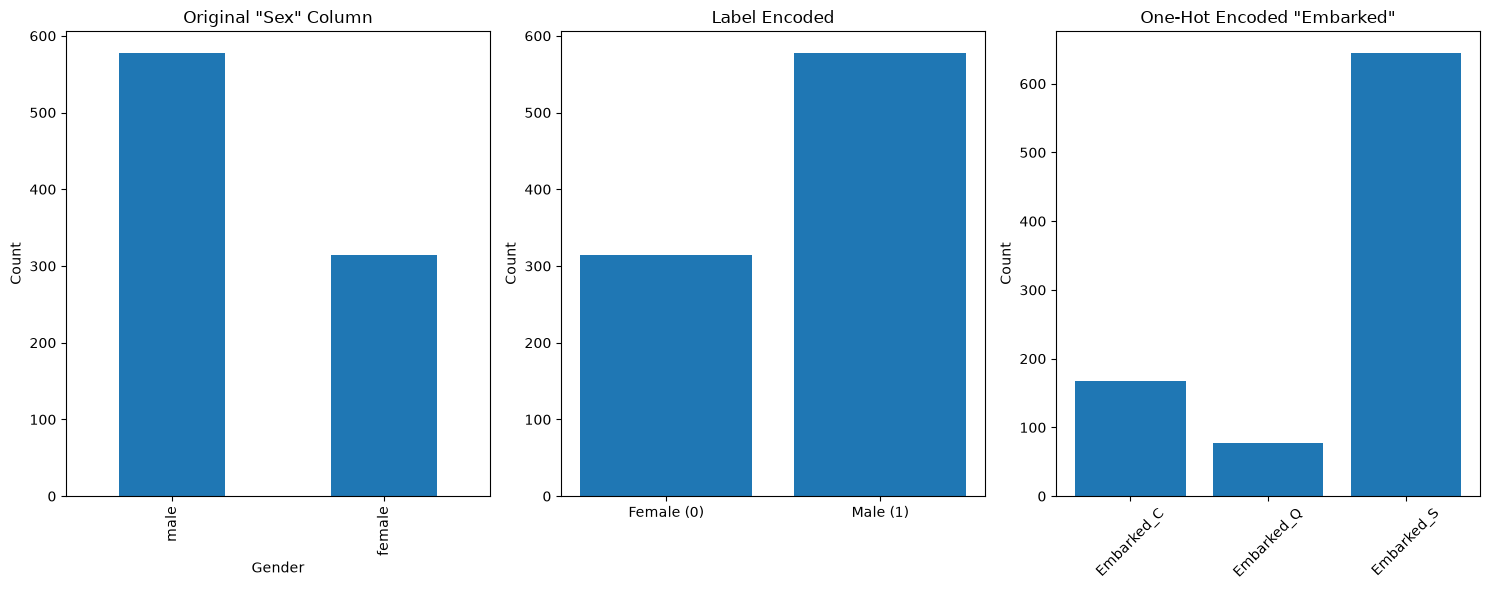

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

# Original Sex
titanic['Sex'].value_counts().plot(
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Original "Sex" Column')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')


# Label Encoded
sex_counts = titanic_encode['Sex_Encoded'].value_counts()

axes[1].bar(
    ['Female (0)', 'Male (1)'],
    [
        sex_counts.get(0, 0),
        sex_counts.get(1, 0)
    ]
)

axes[1].set_title('Label Encoded')
axes[1].set_ylabel('Count')


# One-Hot Encoded
embarked_counts = embarked_dummies.sum()

axes[2].bar(
    embarked_counts.index,
    embarked_counts.values
)

axes[2].set_title('One-Hot Encoded "Embarked"')
axes[2].set_ylabel('Count')

axes[2].tick_params(
    axis='x',
    rotation=45
)

plt.tight_layout()
plt.show()

Observation: Each Embarked category is converted into a separate binary column.The encoded DataFrame demonstrates how categorical port values have been converted into numerical indicators.

6- Encoding Function

In [ ]:
def simple_encode_categorical(data, column_name):
    """Simple function to encode categorical variables"""

    unique_values = data[column_name].nunique()

    print(f"Analyzing '{column_name}':")
    print(f"Has {unique_values} unique values")

    if unique_values == 2:

        print("Binary variable! Use Label Encoding")

        unique_vals = data[column_name].unique()

        mapping = {
            unique_vals[0]: 0,
            unique_vals[1]: 1
        }

        return data[column_name].map(mapping)

    elif unique_values <= 5:

        print("Few categories! Use One-Hot Encoding")

        return pd.get_dummies(
            data[column_name],
            prefix=column_name
        )

    else:

        print(
            "Many categories! Consider if you really need this feature"
        )

        return None

In [ ]:
#Testing ENCODING Function
print("Testing encoding function:")

sex_encoded = simple_encode_categorical(
    titanic,
    'Sex'
)

embarked_encoded = simple_encode_categorical(
    titanic,
    'Embarked'
)

Testing encoding function:
Analyzing 'Sex':
Has 2 unique values
Binary variable! Use Label Encoding
Analyzing 'Embarked':
Has 3 unique values
Few categories! Use One-Hot Encoding


7- Feature Transformation -Skewed data

In [ ]:
#Check Fare Statistics
print("'Fare' statistics:")

print(
    f"Mean: {titanic['Fare'].mean():.2f}"
)

print(
    f"Median: {titanic['Fare'].median():.2f}"
)

print(
    f"Skewness: {titanic['Fare'].skew():.2f}"
)

'Fare' statistics:
Mean: 32.20
Median: 14.45
Skewness: 4.79


Observation: The mean shows the average fare paid by passengers.

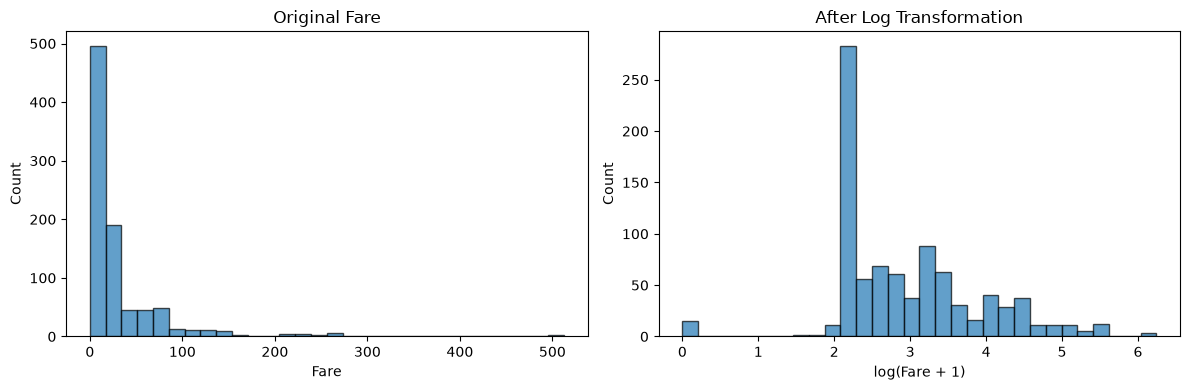

In [ ]:
#before and after view
titanic_transform = titanic.copy()

plt.figure(figsize=(12, 4))

# Original Fare
plt.subplot(1, 2, 1)

plt.hist(
    titanic_transform['Fare'],
    bins=30,
    edgecolor='black',
    alpha=0.7
)

plt.title('Original Fare')
plt.xlabel('Fare')
plt.ylabel('Count')


# Log transformation
titanic_transform['Fare_Log'] = np.log(
    titanic_transform['Fare'] + 1
)

plt.subplot(1, 2, 2)

plt.hist(
    titanic_transform['Fare_Log'],
    bins=30,
    edgecolor='black',
    alpha=0.7
)

plt.title('After Log Transformation')
plt.xlabel('log(Fare + 1)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
#Check Skewness After Transformation
print(
    f"Original skewness: "
    f"{titanic_transform['Fare'].skew():.2f}"
)

print(
    f"After transformation: "
    f"{titanic_transform['Fare_Log'].skew():.2f}"
)

Original skewness: 4.79
After transformation: 0.39


8- Scaling data

In [ ]:
def min_max_scale(data):
    """Simple min-max scaling: (x - min) / (max - min)"""

    return (
        (data - data.min()) /
        (data.max() - data.min())
    )


titanic_transform['Age_Scaled'] = min_max_scale(
    titanic_transform['Age']
)

titanic_transform['Fare_Scaled'] = min_max_scale(
    titanic_transform['Fare']
)

print("Age:")
print(
    titanic_transform['Age_Scaled'].min(),
    "to",
    titanic_transform['Age_Scaled'].max()
)

print("\nFare:")
print(
    titanic_transform['Fare_Scaled'].min(),
    "to",
    titanic_transform['Fare_Scaled'].max()
)

Age:
0.0 to 1.0

Fare:
0.0 to 1.0


In [ ]:
#Standarization
def standardize(data):
    """Simple standardization: (x - mean) / std"""

    return (
        (data - data.mean()) /
        data.std()
    )


titanic_transform['Age_Standardized'] = standardize(
    titanic_transform['Age']
)

titanic_transform['Fare_Standardized'] = standardize(
    titanic_transform['Fare']
)

print(
    "Age standardized mean:",
    titanic_transform['Age_Standardized'].mean()
)

print(
    "Age standardized std:",
    titanic_transform['Age_Standardized'].std()
)

Age standardized mean: 2.338621049070358e-16
Age standardized std: 1.0


Observation: The custom function converts values using (x - mean) / standard deviation.

### 8- 📌Feature Scaling

In [ ]:
#standard_scaler
standard_scaler = StandardScaler()

X_standard = standard_scaler.fit_transform(
    X_train[numeric_features].fillna(
        X_train[numeric_features].median()
    )
)

pd.DataFrame(
    X_standard,
    columns=numeric_features
).head()

,age,fare,sibsp,parch
0,-0.081135,0.513812,-0.465084,-0.466183
1,-0.081135,-0.662563,-0.465084,-0.466183
2,-0.081135,3.955399,-0.465084,-0.466183
3,-0.887827,-0.467874,-0.465084,0.727782
4,0.110934,-0.115977,0.478335,0.727782


Observation: StandardScaler standardizes the selected numerical training features after filling missing values with their medians.

In [ ]:
#minmax_scaler 
from sklearn.preprocessing import MinMaxScaler
minmax_scaler = MinMaxScaler()

X_minmax = minmax_scaler.fit_transform(
    X_train[numeric_features].fillna(
        X_train[numeric_features].median()
    )
)

pd.DataFrame(
    X_minmax,
    columns=numeric_features
).head()

,age,fare,sibsp,parch
0,0.352852,0.110272,0.000,0.000000
1,0.352852,0.000000,0.000,0.000000
2,0.352852,0.432884,0.000,0.000000
3,0.220910,0.018250,0.000,0.166667
4,0.384267,0.051237,0.125,0.166667


Observation: MinMaxScaler transforms numerical features into a common range of 0 to 1.

In [ ]:
#robust_scaler
from sklearn.preprocessing import RobustScaler
robust_scaler = RobustScaler()

X_robust = robust_scaler.fit_transform(
    X_train[numeric_features].fillna(
        X_train[numeric_features].median()
    )
)

pd.DataFrame(
    X_robust,
    columns=numeric_features
).head()

,age,fare,sibsp,parch
0,0.000000,1.819652,0.0,0.0
1,0.000000,-0.625609,0.0,0.0
2,0.000000,8.973477,0.0,0.0
3,-0.750000,-0.220921,0.0,1.0
4,0.178571,0.510548,1.0,1.0


Observation: RobustScaler is less affected by outliers because it uses median and interquartile range.

In [ ]:
#quantile_scaler 
from sklearn.preprocessing import QuantileTransformer
quantile_scaler = QuantileTransformer(
    output_distribution='normal',
    random_state=42
)

X_quantile = quantile_scaler.fit_transform(
    X_train[numeric_features].fillna(
        X_train[numeric_features].median()
    )
)

pd.DataFrame(
    X_quantile,
    columns=numeric_features
).head()

,age,fare,sibsp,parch
0,-0.001763,1.049491,-5.199338,-5.199338
1,-0.001763,-5.199338,-5.199338,-5.199338
2,-0.001763,2.157814,-5.199338,-5.199338
3,-1.102965,-0.356429,-5.199338,0.945145
4,0.401892,0.457967,0.875773,0.945145


Observation: QuantileTransformer transforms the distribution and attempts to make the numerical features more normally distributed.

In [ ]:
#Fare Binning
fare_bins = [0, 10, 50, 100, 600]

fare_labels = [
    'Very_Low',
    'Low',
    'Medium',
    'High'
]

X_train_df['fare_bin'] = pd.cut(
    X_train['fare'],
    bins=fare_bins,
    labels=fare_labels
)

X_test_df['fare_bin'] = pd.cut(
    X_test['fare'],
    bins=fare_bins,
    labels=fare_labels
)

Observation: Fare values are divided into four groups based on predefined ranges.

In [ ]:
#one hot Encode Free bin
fare_bin_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

fare_bin_train_encoded = fare_bin_encoder.fit_transform(
    X_train_df[['fare_bin']]
)

fare_bin_test_encoded = fare_bin_encoder.transform(
    X_test_df[['fare_bin']]
)

In [ ]:
#add fare bin colummn
fare_bin_columns = fare_bin_encoder.get_feature_names_out(
    ['fare_bin']
)

X_train_df[fare_bin_columns] = fare_bin_train_encoded
X_test_df[fare_bin_columns] = fare_bin_test_encoded

Observation: The encoded fare-bin features are added to the training and testing DataFrames.

In [ ]:
#Remove fare bin column
X_train_df.drop(
    columns=['fare_bin'],
    inplace=True
)

X_test_df.drop(
    columns=['fare_bin'],
    inplace=True
)

Observation: The original categorical fare_bin column is removed because its encoded versions are already available.

In [ ]:
#final dataset
print("Final Training Shape:", X_train_df.shape)
print("Final Testing Shape:", X_test_df.shape)

X_train_df.head()

Final Training Shape: (712, 25)
Final Testing Shape: (179, 25)


,num__age,num__fare,num__sibsp,num__parch,cat__sex_female,cat__sex_male,cat__embarked_C,cat__embarked_Q,cat__embarked_S,cat__embarked_nan,...,cat__who_woman,cat__adult_male_False,cat__adult_male_True,cat__alone_False,cat__alone_True,fare_bin_High,fare_bin_Low,fare_bin_Medium,fare_bin_Very_Low,fare_bin_nan
692,NaN,0.513812,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
481,NaN,-0.662563,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
527,NaN,3.955399,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
855,-0.815864,-0.467874,-0.465084,0.727782,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
801,0.082384,-0.115977,0.478335,0.727782,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
#final missing value check
print("Final Training Missing Values:")
print(X_train_df.isnull().sum().sum())

print("\nFinal Testing Missing Values:")
print(X_test_df.isnull().sum().sum())

Final Training Missing Values:
137

Final Testing Missing Values:
40


In [ ]:
#final Target data
print("y_train:")
print(y_train.head())

print("\ny_test:")
print(y_test.head())

y_train:
692    1
481    0
527    0
855    1
801    1
Name: survived, dtype: int64

y_test:
565    0
160    0
553    1
860    0
241    1
Name: survived, dtype: int64
